# Standard TCT vs Adaptive TCT

Compares the two TCT accountants at a **predetermined number of tops τ**.

| Accountant | Charge per user | Requires τ upfront? |
|---|---|---|
| Standard TCT | K_τ · ε once at registration | Yes |
| Adaptive TCT | K_1·ε at registration + increments per hit | No |

**Key question:** For a given τ, standard TCT charges K_τ^{standard} which uses the full δ budget on one level.  
Adaptive TCT charges K_{τ+1}^{adaptive} which splits δ across all k ≥ 1 via Zeta-2.  
This makes standard TCT cheaper for the specific τ — but it requires committing to τ in advance.

**Sections:**
1. Theoretical cost curves — K_τ for both accountants vs τ
2. Single-user budget trace — how each accountant drains budget for one user
3. Budget remaining at the τ-th hit — sweep over τ
4. Population simulation — average budget remaining across the full population

In [9]:
import sys
sys.path.insert(0, '..')

import math
import numpy as np
import matplotlib.pyplot as plt

from simulation.population import User
from simulation.accountants.adaptive_tct import AdaptiveTCTAccountant
from simulation.accountants.standard_tct import StandardTCTAccountant
from simulation.calibration import q_from_epsilon, set_threshold_for_hit_rate
from simulation.datasets import generate_synthetic_population, PopulationConfig
from simulation.environment import SimulationEnvironment

plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})

In [10]:
# ── Parameters ───────────────────────────────────────────────────────────────
EPSILON = 0.1
DELTA   = 1e-3
TAU_MAX = 50     # maximum τ to plot in theory section

q = q_from_epsilon(EPSILON)
print(f'ε={EPSILON}, δ={DELTA}, q={q:.4f} (Lemma 2.3)')

ε=0.1, δ=0.001, q=0.4750 (Lemma 2.3)


## Section 1: Theoretical Cost Curves

For each predetermined τ, how many compositions (and how much ε) does each accountant charge?

- **Standard TCT**: K_τ^{standard} · ε upfront (uses full δ on one target)  
- **Adaptive TCT**: K_{τ+1}^{adaptive} · ε total after τ actual hits (splits δ via Zeta-2)

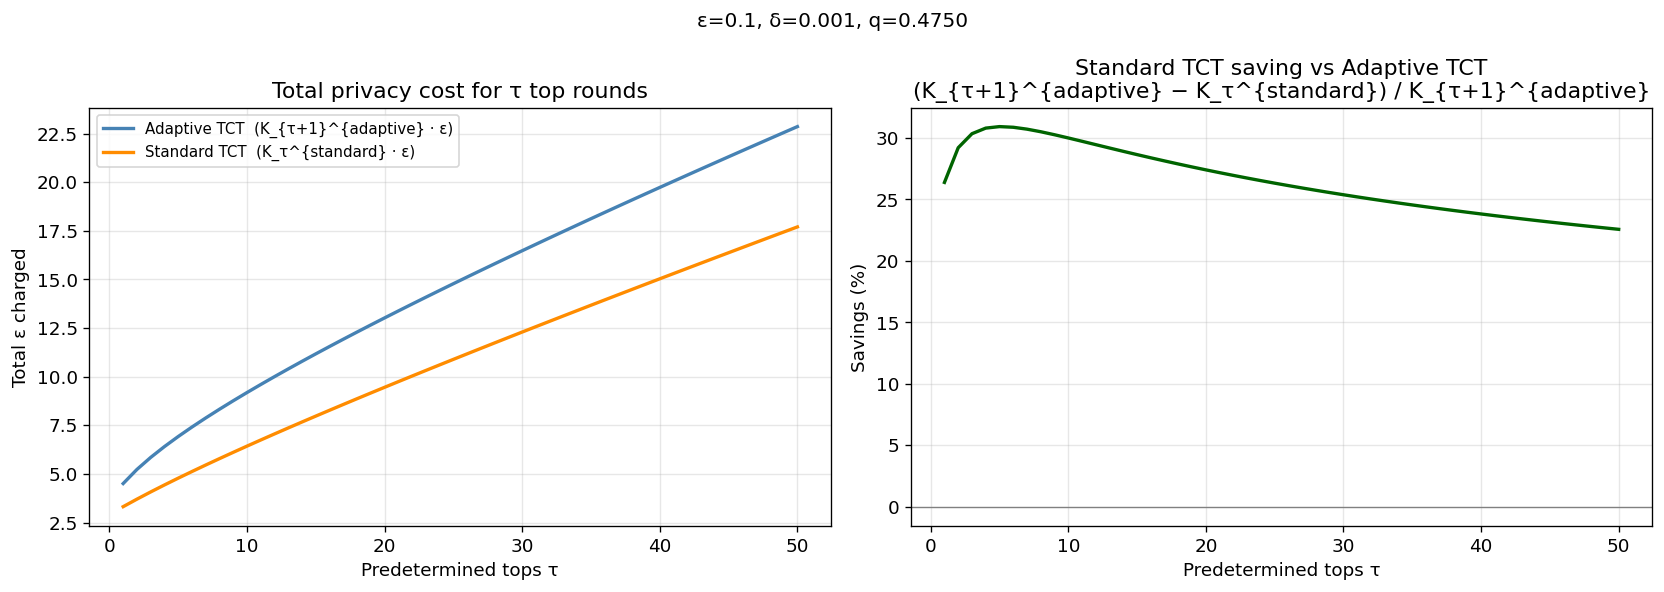

   τ    Adaptive ε    Standard ε    Saving
------------------------------------------
   1         4.504         3.316     26.4%
   2         5.230         3.703     29.2%
   5         6.922         4.782     30.9%
  10         9.185         6.429     30.0%
  20        13.023         9.454     27.4%
  50        22.859        17.701     22.6%


In [11]:
tau_vals = list(range(1, TAU_MAX + 1))

# Standard TCT: K_tau using full delta
def K_standard(tau, epsilon=EPSILON, delta=DELTA):
    q = q_from_epsilon(epsilon)
    beta = math.log(1.0 / delta)
    alpha = (beta + math.sqrt(beta**2 + 2*beta*tau)) / tau
    return (1 + alpha) / q * tau

# Adaptive TCT: K_{tau+1} after tau actual hits
def K_adaptive_after_tau(tau, epsilon=EPSILON, delta=DELTA):
    acc = AdaptiveTCTAccountant(epsilon=epsilon, delta=delta)
    return acc.compositions(tau + 1)

K_std  = [K_standard(t) * EPSILON          for t in tau_vals]
K_adap = [K_adaptive_after_tau(t) * EPSILON for t in tau_vals]

savings = [(K_adap[i] - K_std[i]) / K_adap[i] * 100 for i in range(len(tau_vals))]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.plot(tau_vals, K_adap, color='steelblue',  lw=2, label='Adaptive TCT  (K_{τ+1}^{adaptive} · ε)')
ax.plot(tau_vals, K_std,  color='darkorange', lw=2, label='Standard TCT  (K_τ^{standard} · ε)')
ax.set_xlabel('Predetermined tops τ')
ax.set_ylabel('Total ε charged')
ax.set_title('Total privacy cost for τ top rounds')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(tau_vals, savings, color='darkgreen', lw=2)
ax.axhline(0, color='gray', lw=0.8)
ax.set_xlabel('Predetermined tops τ')
ax.set_ylabel('Savings (%)')
ax.set_title('Standard TCT saving vs Adaptive TCT\n(K_{τ+1}^{adaptive} − K_τ^{standard}) / K_{τ+1}^{adaptive}')
ax.grid(True, alpha=0.3)

plt.suptitle(f'ε={EPSILON}, δ={DELTA}, q={q:.4f}', fontsize=12)
plt.tight_layout()
plt.show()

print(f'{"τ":>4}  {"Adaptive ε":>12}  {"Standard ε":>12}  {"Saving":>8}')
print('-' * 42)
for t in [1, 2, 5, 10, 20, 50]:
    j = t - 1
    print(f'{t:>4}  {K_adap[j]:>12.3f}  {K_std[j]:>12.3f}  {savings[j]:>7.1f}%')